# Streamlined simulations

## ICRA 2026

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("runs/iros_26/results_evrp_latest.csv")
# (Optional) Compute an 'energy' column if you also want to plot energy consumption.
df['energy'] = df['ev_distance'] + 0.01*df['drone_distance']
df.head()

,num_evs,num_tasks,ev_range,maze_loop_percentage,maze_size,bms,timesteps,num_tasks_finished,ev_distance,drone_distance,energy
0,4,28,4500,90,35,1,80,28,296.0,527.360207,301.273602
1,4,28,4500,90,35,0,77,28,294.0,0.000000,294.000000
2,4,27,4500,90,35,1,79,27,290.0,534.647677,295.346477
3,4,29,4500,90,35,0,77,29,302.0,0.000000,302.000000
4,4,30,4500,90,35,1,82,30,306.0,520.501058,311.205011


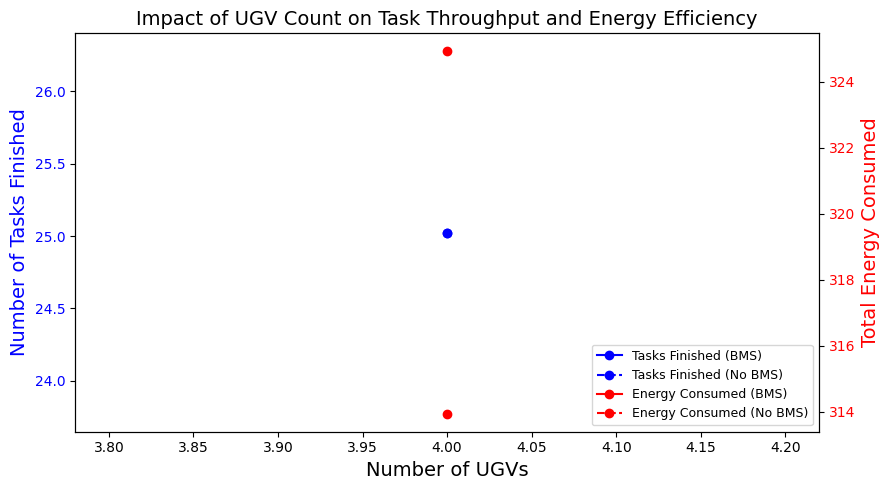

In [6]:
import pandas as pd
import matplotlib.pyplot as plt


# Split the data into BMS and no-BMS cases
df_bms = df[df['bms'] == 1]
df_no_bms = df[df['bms'] == 0]

# Aggregate by number of EVs (here using the mean for each metric)
group_bms = df_bms.groupby('num_evs').mean().reset_index()
group_no_bms = df_no_bms.groupby('num_evs').mean().reset_index()

# Create the dual-axis plot
fig, axs = plt.subplots(figsize=(9, 5))
ax1 = axs
ax2 = axs.twinx()

# Plot number of tasks finished on the left y-axis
ax1.plot(group_bms['num_evs'], group_bms['num_tasks_finished'], 'b-o', label='Tasks Finished (BMS)')
ax1.plot(group_no_bms['num_evs'], group_no_bms['num_tasks_finished'], 'b--o', label='Tasks Finished (No BMS)')
ax1.set_xlabel('Number of UGVs', fontsize=14)
ax1.set_ylabel('Number of Tasks Finished', color='b', fontsize=14)
ax1.tick_params(axis='y', labelcolor='b')

# Plot EV distance (as an energy consumption proxy) on the right y-axis
ax2.plot(group_bms['num_evs'], group_bms['energy'], 'r-o', label='Energy Consumed (BMS)')
ax2.plot(group_no_bms['num_evs'], group_no_bms['energy'], 'r--o', label='Energy Consumed (No BMS)')
ax2.set_ylabel('Total Energy Consumed', color='r', fontsize=14)
ax2.tick_params(axis='y', labelcolor='r')

# Combine legends from both axes
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower right', fontsize=9)

plt.title('Impact of UGV Count on Task Throughput and Energy Efficiency', fontsize=14)
plt.tight_layout()

plt.show()


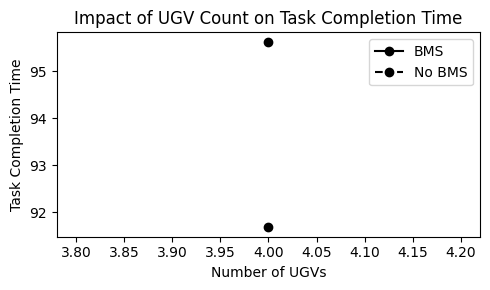

In [7]:
import pandas as pd
import matplotlib.pyplot as plt


# Assuming df is already defined

param = 'num_evs'
metric = 'timesteps'

# Group the DataFrame by 'bms' and the chosen parameter, taking the average of the selected metric
grouped = df.groupby(['bms', param], as_index=False)[metric].mean()

# Split into BMS (1) and No BMS (0) cases
df_yes_bms = grouped[grouped['bms'] == 1]
df_no_bms = grouped[grouped['bms'] == 0]

# Create a figure and axis similar to the first plot
fig, ax = plt.subplots(figsize=(5, 3))

# Plot BMS (solid blue with circle markers) and No BMS (dashed blue with circle markers)
ax.plot(df_yes_bms[param], df_yes_bms[metric], 'k-o', label='BMS')
ax.plot(df_no_bms[param], df_no_bms[metric], 'k--o', label='No BMS')

# Label the axes and add a title
ax.set_xlabel('Number of UGVs')
ax.set_ylabel('Task Completion Time', color='k')
ax.tick_params(axis='y', labelcolor='k')
ax.set_title('Impact of UGV Count on Task Completion Time')

# Place the legend in the upper right, similar to the first plot
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


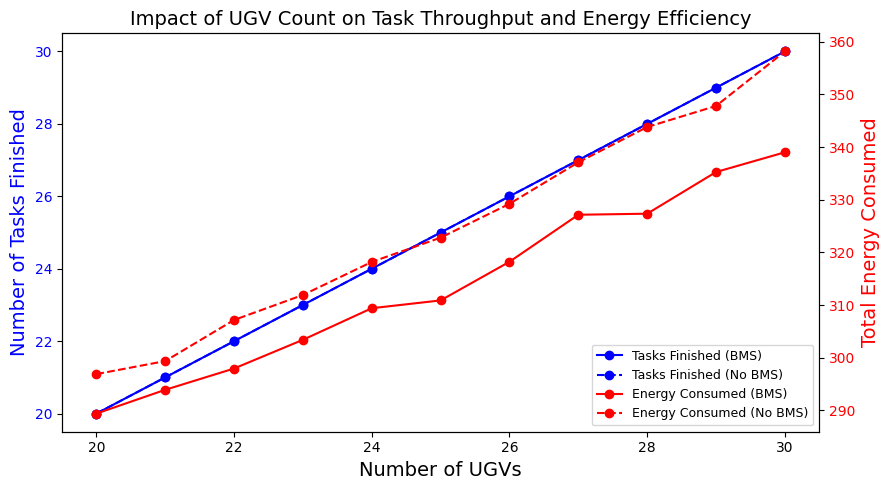

In [8]:
import pandas as pd
import matplotlib.pyplot as plt


# Split the data into BMS and no-BMS cases
df_bms = df[df['bms'] == 1]
df_no_bms = df[df['bms'] == 0]

# Aggregate by number of EVs (here using the mean for each metric)
group_bms = df_bms.groupby('num_tasks').mean().reset_index()
group_no_bms = df_no_bms.groupby('num_tasks').mean().reset_index()

# Create the dual-axis plot
fig, axs = plt.subplots(figsize=(9, 5))
ax1 = axs
ax2 = axs.twinx()

# Plot number of tasks finished on the left y-axis
ax1.plot(group_bms['num_tasks'], group_bms['num_tasks_finished'], 'b-o', label='Tasks Finished (BMS)')
ax1.plot(group_no_bms['num_tasks'], group_no_bms['num_tasks_finished'], 'b--o', label='Tasks Finished (No BMS)')
ax1.set_xlabel('Number of UGVs', fontsize=14)
ax1.set_ylabel('Number of Tasks Finished', color='b', fontsize=14)
ax1.tick_params(axis='y', labelcolor='b')

# Plot EV distance (as an energy consumption proxy) on the right y-axis
ax2.plot(group_bms['num_tasks'], group_bms['energy'], 'r-o', label='Energy Consumed (BMS)')
ax2.plot(group_no_bms['num_tasks'], group_no_bms['energy'], 'r--o', label='Energy Consumed (No BMS)')
ax2.set_ylabel('Total Energy Consumed', color='r', fontsize=14)
ax2.tick_params(axis='y', labelcolor='r')

# Combine legends from both axes
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower right', fontsize=9)

plt.title('Impact of UGV Count on Task Throughput and Energy Efficiency', fontsize=14)
plt.tight_layout()

plt.show()


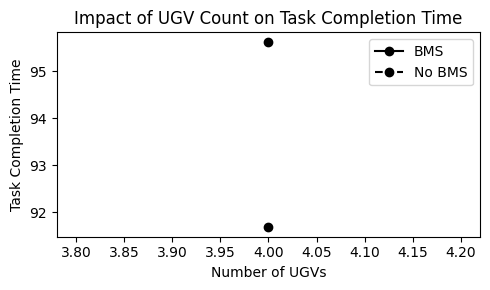

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


# Assuming df is already defined

param = 'num_evs'
metric = 'timesteps'

# Group the DataFrame by 'bms' and the chosen parameter, taking the average of the selected metric
grouped = df.groupby(['bms', param], as_index=False)[metric].mean()

# Split into BMS (1) and No BMS (0) cases
df_yes_bms = grouped[grouped['bms'] == 1]
df_no_bms = grouped[grouped['bms'] == 0]

# Create a figure and axis similar to the first plot
fig, ax = plt.subplots(figsize=(5, 3))

# Plot BMS (solid blue with circle markers) and No BMS (dashed blue with circle markers)
ax.plot(df_yes_bms[param], df_yes_bms[metric], 'k-o', label='BMS')
ax.plot(df_no_bms[param], df_no_bms[metric], 'k--o', label='No BMS')

# Label the axes and add a title
ax.set_xlabel('Number of UGVs')
ax.set_ylabel('Task Completion Time', color='k')
ax.tick_params(axis='y', labelcolor='k')
ax.set_title('Impact of UGV Count on Task Completion Time')

# Place the legend in the upper right, similar to the first plot
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


## Baseline

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

df = pd.read_csv("runs/iros_26/results_mtsp_v_evrp_reachable.csv", sep=';')
df['feasibility'] = df['feasibility'].astype(str).str.strip().str.lower().map({'true': 1, 'false': 0})
df_mtsp = df[df['planner'] == 'mtsp']
df_evrp = df[df['planner'] == 'evrp']
df.head()


,planner,num_evs,num_tasks,ev_range,maze_loop_percentage,maze_size,timesteps,num_tasks_finished,ev_distance,feasibility,evrp_callback,task_order
0,mtsp,4,21,4500,90,35,135,21,350.0,1,2,"[[(14, 25), (7, 23), (5, 27), (13, 23)], [(23,..."
1,evrp,4,21,4500,90,35,56,21,203.0,1,0,"[[(14, 25), (13, 23), (7, 23), (5, 27), (13, 3..."
2,mtsp,4,20,4500,90,35,135,20,338.0,1,2,"[[(14, 25), (7, 23), (5, 27), (13, 23)], [(3, ..."
3,evrp,4,20,4500,90,35,67,20,206.0,1,0,"[[(23, 5), (28, 5), (33, 4), (33, 6), (33, 14)..."
4,mtsp,4,23,4500,90,35,135,23,377.0,1,2,"[[(3, 4), (10, 6), (9, 9), (3, 9), (8, 14)], [..."


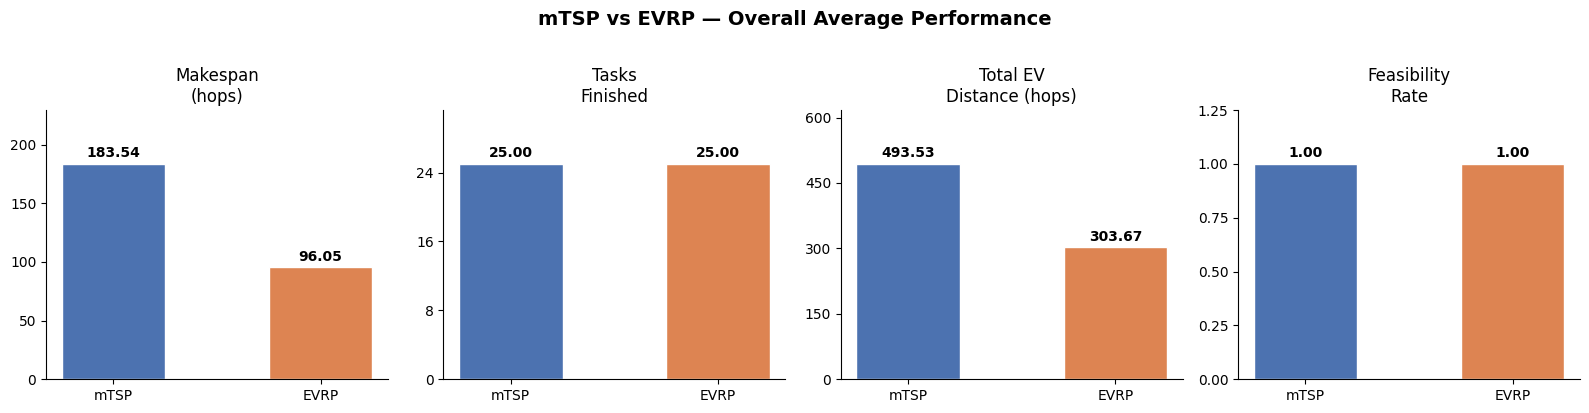

In [2]:
# ── Overall averages: mTSP vs EVRP ──────────────────────────────────────────
metrics     = ['timesteps', 'num_tasks_finished', 'ev_distance', 'feasibility']
labels      = ['Makespan\n(hops)', 'Tasks\nFinished', 'Total EV\nDistance (hops)', 'Feasibility\nRate']
colors      = ['#4C72B0', '#DD8452']
planner_lbl = ['mTSP', 'EVRP']

means = [df_mtsp[m].mean() for m in metrics], [df_evrp[m].mean() for m in metrics]

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, metric, label, (v_mtsp, v_evrp) in zip(axs, metrics, labels,
                                                 zip(means[0], means[1])):
    bars = ax.bar(planner_lbl, [v_mtsp, v_evrp], color=colors, width=0.5, edgecolor='white')
    for bar, val in zip(bars, [v_mtsp, v_evrp]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.02,
                f'{val:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_title(label, fontsize=12)
    ax.set_ylim(0, max(v_mtsp, v_evrp) * 1.25)
    ax.spines[['top', 'right']].set_visible(False)
    ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

fig.suptitle('mTSP vs EVRP — Overall Average Performance', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


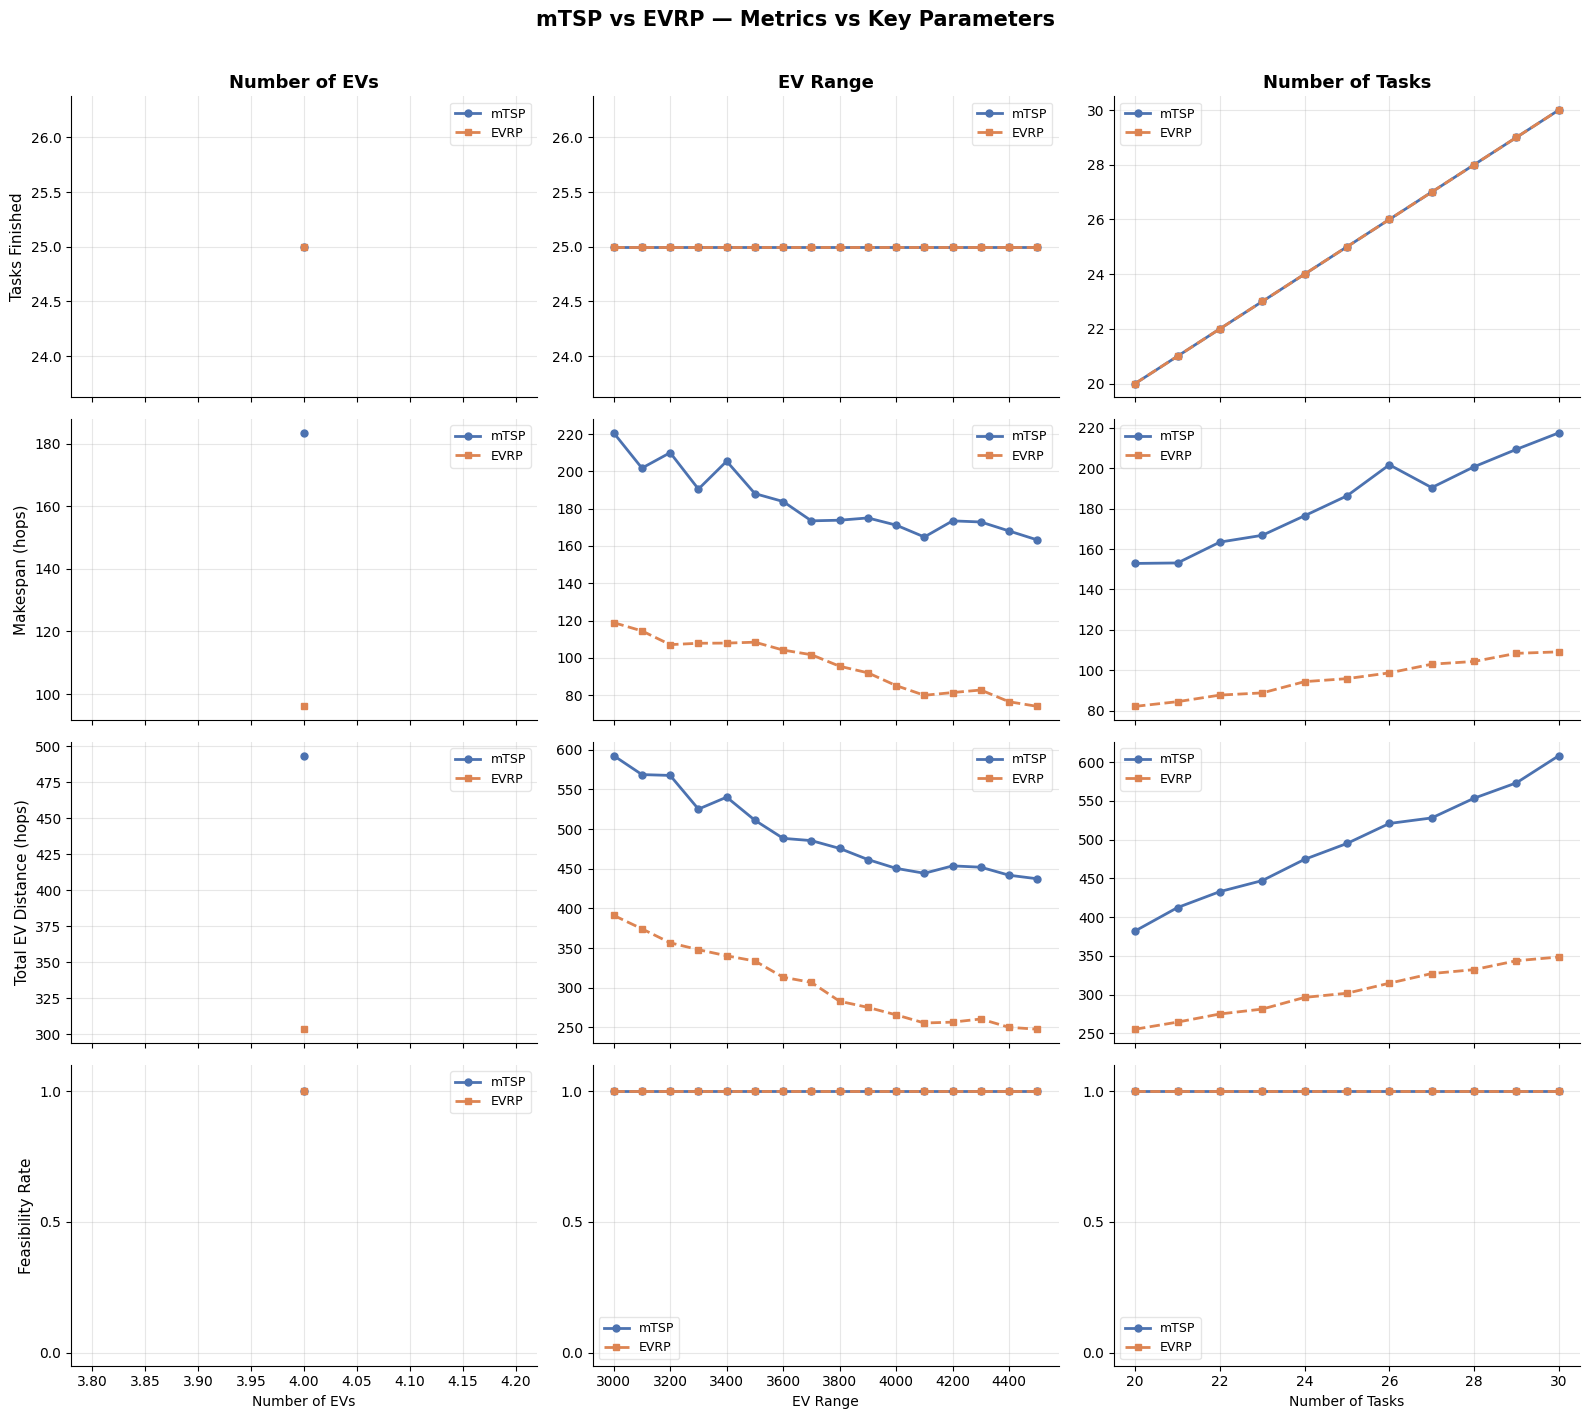

In [3]:
# ── Per-parameter comparison: grouped line plots ────────────────────────────
params      = ['num_evs', 'ev_range', 'num_tasks']
param_lbls  = ['Number of EVs', 'EV Range', 'Number of Tasks']
plot_metrics = [
    ('num_tasks_finished', 'Tasks Finished'),
    ('timesteps',          'Makespan (hops)'),
    ('ev_distance',        'Total EV Distance (hops)'),
    ('feasibility',        'Feasibility Rate'),
]

fig, axs = plt.subplots(len(plot_metrics), len(params),
                         figsize=(16, 14), sharex='col')

for col, (param, plbl) in enumerate(zip(params, param_lbls)):
    g_mtsp = df_mtsp.groupby(param).mean(numeric_only=True).reset_index()
    g_evrp = df_evrp.groupby(param).mean(numeric_only=True).reset_index()

    for row, (metric, mlbl) in enumerate(plot_metrics):
        ax = axs[row, col]
        ax.plot(g_mtsp[param], g_mtsp[metric], 'o-',  color=colors[0],
                linewidth=2, markersize=5, label='mTSP')
        ax.plot(g_evrp[param], g_evrp[metric], 's--', color=colors[1],
                linewidth=2, markersize=5, label='EVRP')
        if row == 0:
            ax.set_title(plbl, fontsize=13, fontweight='bold')
        if col == 0:
            ax.set_ylabel(mlbl, fontsize=11)
        ax.set_xlabel(plbl if row == len(plot_metrics)-1 else '', fontsize=10)
        ax.legend(fontsize=9, framealpha=0.5)
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(True, alpha=0.3)
        if metric == 'feasibility':
            ax.set_ylim(-0.05, 1.1)
            ax.yaxis.set_major_locator(ticker.FixedLocator([0, 0.5, 1.0]))

fig.suptitle('mTSP vs EVRP — Metrics vs Key Parameters', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


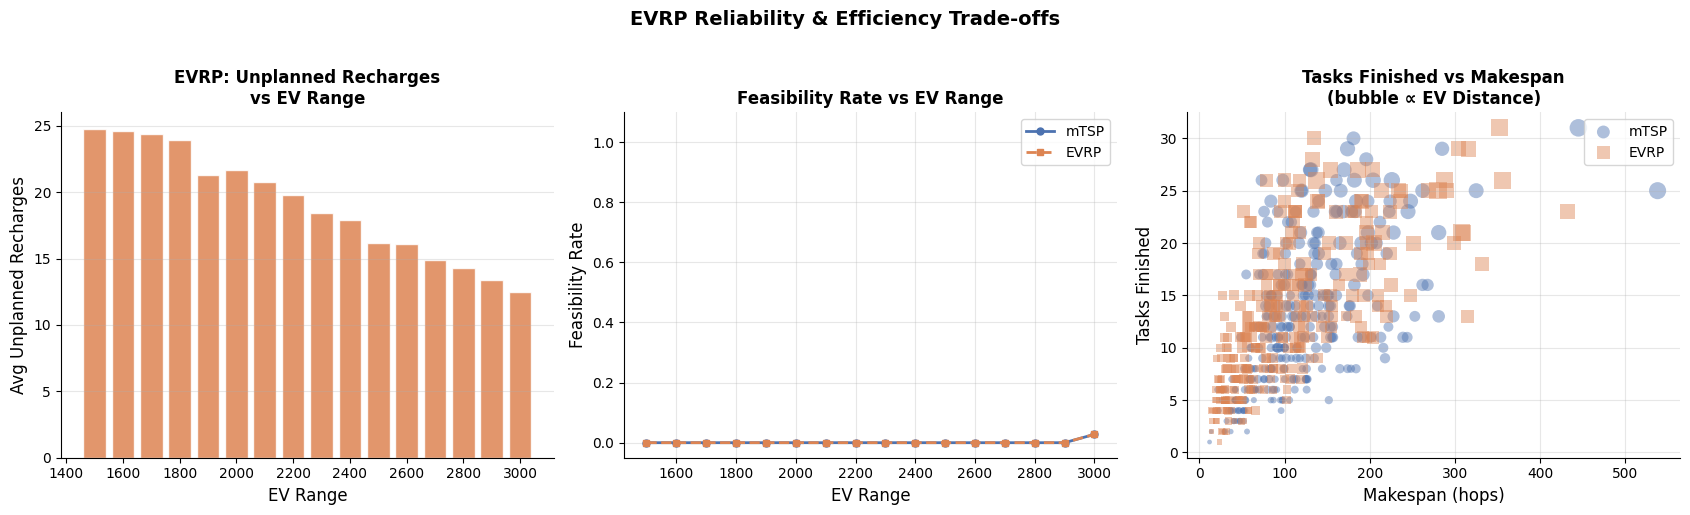

In [13]:
# ── EVRP callback (unplanned recharges) & efficiency scatter ────────────────
fig, axs = plt.subplots(1, 3, figsize=(17, 5))

# 1. evrp_callback distribution (EVRP only, by ev_range)
ax = axs[0]
cb_by_range = df_evrp.groupby('ev_range')['evrp_callback'].mean()
ax.bar(cb_by_range.index, cb_by_range.values, color=colors[1],
       alpha=0.85, width=80, edgecolor='white')
ax.set_xlabel('EV Range', fontsize=12)
ax.set_ylabel('Avg Unplanned Recharges', fontsize=12)
ax.set_title('EVRP: Unplanned Recharges\nvs EV Range', fontsize=12, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)

# 2. Feasibility rate vs ev_range for both planners
ax = axs[1]
feas_mtsp = df_mtsp.groupby('ev_range')['feasibility'].mean()
feas_evrp = df_evrp.groupby('ev_range')['feasibility'].mean()
ax.plot(feas_mtsp.index, feas_mtsp.values, 'o-',  color=colors[0], lw=2, ms=5, label='mTSP')
ax.plot(feas_evrp.index, feas_evrp.values, 's--', color=colors[1], lw=2, ms=5, label='EVRP')
ax.set_xlabel('EV Range', fontsize=12)
ax.set_ylabel('Feasibility Rate', fontsize=12)
ax.set_title('Feasibility Rate vs EV Range', fontsize=12, fontweight='bold')
ax.set_ylim(-0.05, 1.1)
ax.legend(fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=0.3)

# 3. Scatter: Tasks finished vs Makespan (bubble = ev_distance, colour = planner)
ax = axs[2]
for sub_df, lbl, col, mk in [(df_mtsp, 'mTSP', colors[0], 'o'),
                               (df_evrp, 'EVRP', colors[1], 's')]:
    samp = sub_df.sample(min(300, len(sub_df)), random_state=42)
    sc = ax.scatter(samp['timesteps'], samp['num_tasks_finished'],
                    s=samp['ev_distance'] / samp['ev_distance'].max() * 150 + 10,
                    c=col, marker=mk, alpha=0.45, label=lbl, edgecolors='none')
ax.set_xlabel('Makespan (hops)', fontsize=12)
ax.set_ylabel('Tasks Finished', fontsize=12)
ax.set_title('Tasks Finished vs Makespan\n(bubble ∝ EV Distance)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=0.3)

plt.suptitle('EVRP Reliability & Efficiency Trade-offs', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## IROS 26

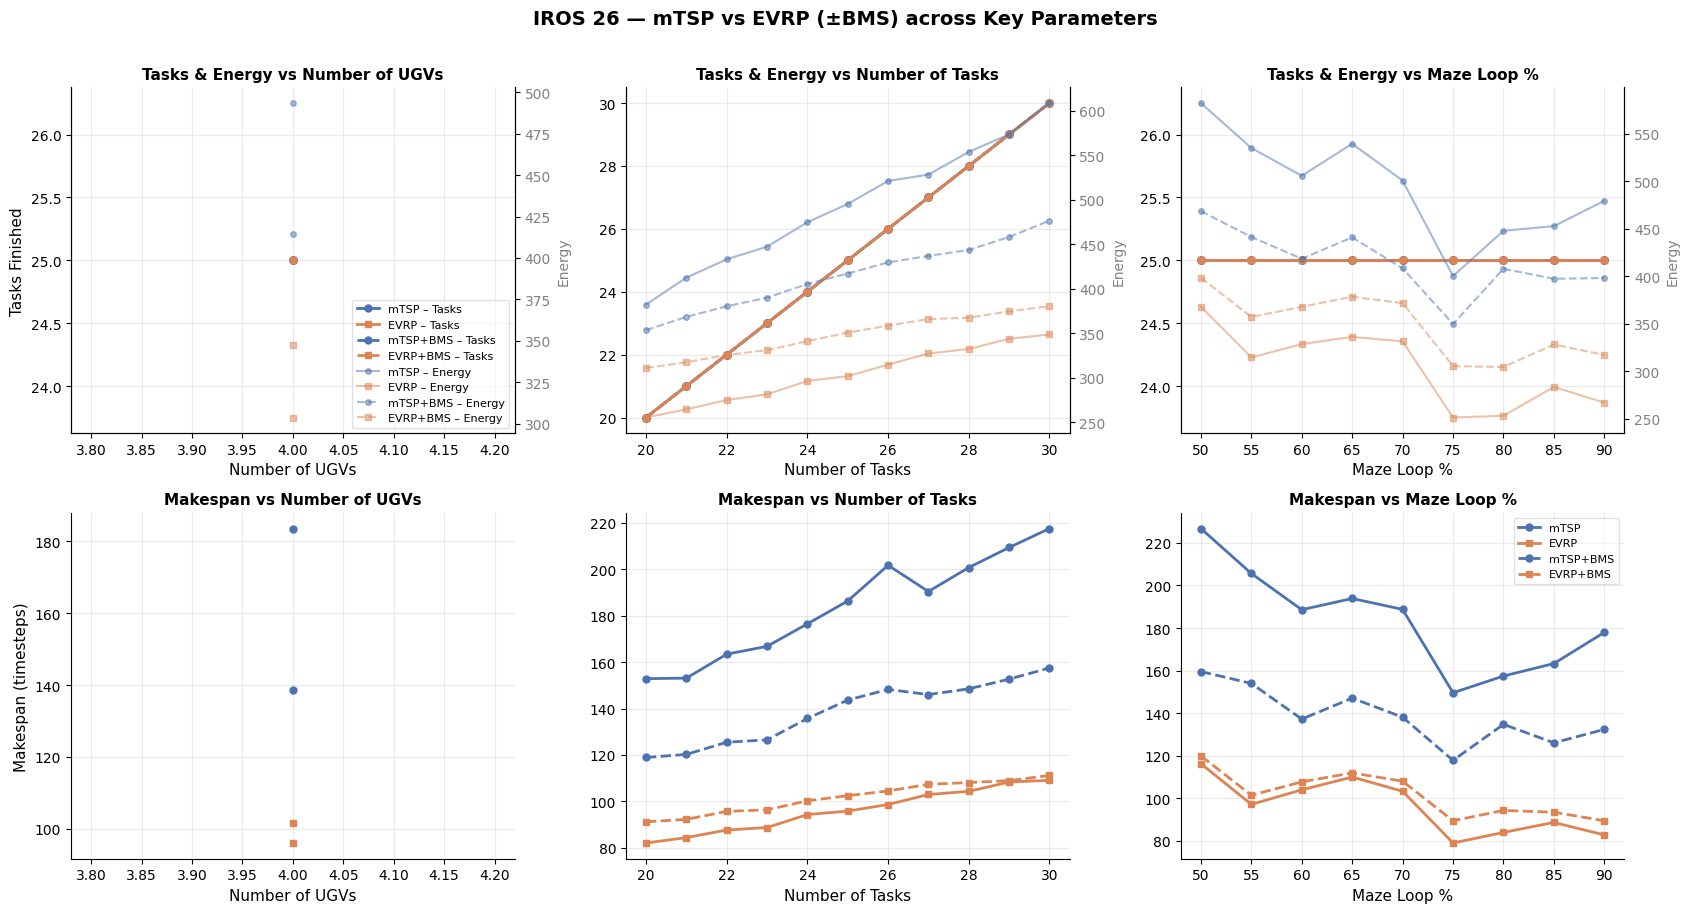

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── Load data ────────────────────────────────────────────────────────────────
df_base = pd.read_csv("runs/iros_26/results_mtsp_v_evrp_reachable.csv", sep=';')
df_mtsp_bms = pd.read_csv("runs/iros_26/results_mtsp_reachable_bms.csv")
df_evrp_bms = pd.read_csv("runs/iros_26/results_evrp_reachable_bms.csv")

# Energy: ev_distance only for non-BMS (no drone col), ev + drone for BMS
df_base['energy'] = df_base['ev_distance']
df_mtsp_bms['energy'] = df_mtsp_bms['ev_distance'] + 0.01 * df_mtsp_bms['drone_distance']
df_evrp_bms['energy'] = df_evrp_bms['ev_distance'] + 0.01 * df_evrp_bms['drone_distance']

df_mtsp     = df_base[df_base['planner'] == 'mtsp']
df_evrp     = df_base[df_base['planner'] == 'evrp']

# ── Plot config ──────────────────────────────────────────────────────────────
params      = ['num_evs',        'num_tasks',      'maze_loop_percentage']
param_lbls  = ['Number of UGVs', 'Number of Tasks', 'Maze Loop %']

methods = [
    (df_mtsp,     'mTSP',      '#4C72B0', 'o',  '-'),
    (df_evrp,     'EVRP',      '#DD8452', 's',  '-'),
    (df_mtsp_bms, 'mTSP+BMS',  '#4C72B0', 'o',  '--'),
    (df_evrp_bms, 'EVRP+BMS',  '#DD8452', 's',  '--'),
]

# ── 6 subplots: 2 rows × 3 cols ──────────────────────────────────────────────
# Row 0: Tasks Finished (left y) + Energy (right y)  vs each x-param
# Row 1: Makespan  vs each x-param
fig, axs = plt.subplots(2, 3, figsize=(17, 9))

for col, (param, plbl) in enumerate(zip(params, param_lbls)):

    # ── Row 0: dual-axis tasks + energy ─────────────────────────────────────
    ax1 = axs[0, col]
    ax2 = ax1.twinx()

    for df_m, lbl, color, mk, ls in methods:
        g = df_m.groupby(param).mean(numeric_only=True).reset_index()
        solid = (ls == '-')
        ax1.plot(g[param], g['num_tasks_finished'],
                 marker=mk, linestyle=ls, color=color,
                 linewidth=2, markersize=5,
                 label=f'{lbl} – Tasks' if col == 0 else '_nolegend_')
        ax2.plot(g[param], g['energy'],
                 marker=mk, linestyle=ls, color=color,
                 linewidth=1.5, markersize=4, alpha=0.5,
                 label=f'{lbl} – Energy' if col == 0 else '_nolegend_')

    ax1.set_xlabel(plbl, fontsize=11)
    if col == 0:
        ax1.set_ylabel('Tasks Finished', color='k', fontsize=11)
    ax2.set_ylabel('Energy', color='grey', fontsize=10)
    ax2.tick_params(axis='y', labelcolor='grey')
    ax1.set_title(f'Tasks & Energy vs {plbl}', fontsize=11, fontweight='bold')
    ax1.spines[['top']].set_visible(False)
    ax2.spines[['top']].set_visible(False)
    ax1.grid(True, alpha=0.25)

    # shared legend on first column only
    if col == 0:
        lines1, labs1 = ax1.get_legend_handles_labels()
        lines2, labs2 = ax2.get_legend_handles_labels()
        ax1.legend(lines1 + lines2, labs1 + labs2,
                   fontsize=8, loc='lower right', framealpha=0.6)

    # ── Row 1: makespan ──────────────────────────────────────────────────────
    ax = axs[1, col]

    for df_m, lbl, color, mk, ls in methods:
        g = df_m.groupby(param).mean(numeric_only=True).reset_index()
        ax.plot(g[param], g['timesteps'],
                marker=mk, linestyle=ls, color=color,
                linewidth=2, markersize=5, label=lbl)

    ax.set_xlabel(plbl, fontsize=11)
    if col == 0:
        ax.set_ylabel('Makespan (timesteps)', fontsize=11)
    ax.set_title(f'Makespan vs {plbl}', fontsize=11, fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(True, alpha=0.25)
    if col == 2:
        ax.legend(fontsize=8, framealpha=0.6)

fig.suptitle('IROS 26 — mTSP vs EVRP (±BMS) across Key Parameters',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


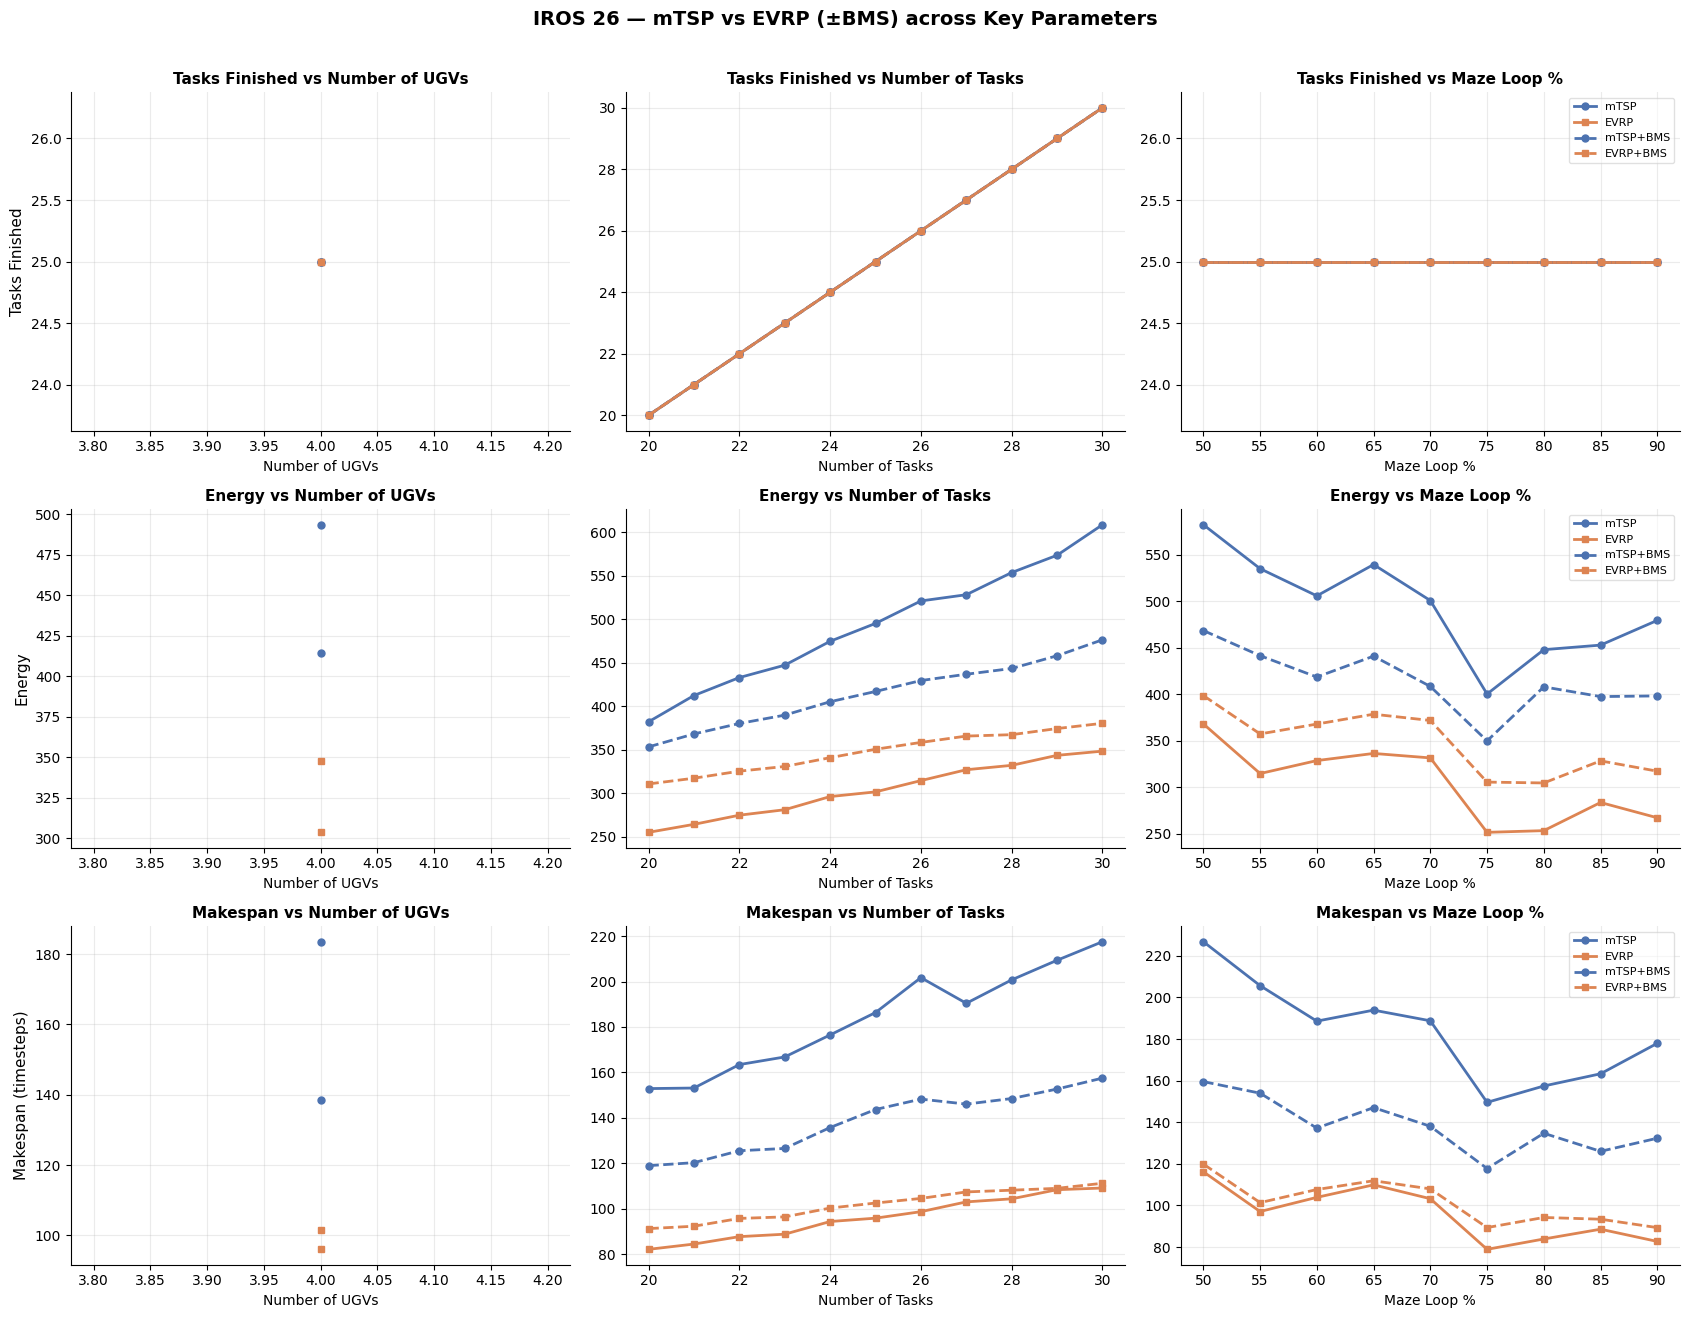

In [3]:

# ── 9 subplots: 3 rows × 3 cols ──────────────────────────────────────────────
# Row 0: Tasks Finished  vs each x-param
# Row 1: Energy          vs each x-param
# Row 2: Makespan        vs each x-param
fig, axs = plt.subplots(3, 3, figsize=(17, 13))

for col, (param, plbl) in enumerate(zip(params, param_lbls)):

    # ── Row 0: Tasks Finished ────────────────────────────────────────────────
    ax = axs[0, col]
    for df_m, lbl, color, mk, ls in methods:
        g = df_m.groupby(param).mean(numeric_only=True).reset_index()
        ax.plot(g[param], g['num_tasks_finished'],
                marker=mk, linestyle=ls, color=color,
                linewidth=2, markersize=5, label=lbl)
    ax.set_title(f'Tasks Finished vs {plbl}', fontsize=11, fontweight='bold')
    if col == 0:
        ax.set_ylabel('Tasks Finished', fontsize=11)
    ax.set_xlabel(plbl, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(True, alpha=0.25)
    if col == 2:
        ax.legend(fontsize=8, framealpha=0.6)

    # ── Row 1: Energy ────────────────────────────────────────────────────────
    ax = axs[1, col]
    for df_m, lbl, color, mk, ls in methods:
        g = df_m.groupby(param).mean(numeric_only=True).reset_index()
        ax.plot(g[param], g['energy'],
                marker=mk, linestyle=ls, color=color,
                linewidth=2, markersize=5, label=lbl)
    ax.set_title(f'Energy vs {plbl}', fontsize=11, fontweight='bold')
    if col == 0:
        ax.set_ylabel('Energy', fontsize=11)
    ax.set_xlabel(plbl, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(True, alpha=0.25)
    if col == 2:
        ax.legend(fontsize=8, framealpha=0.6)

    # ── Row 2: Makespan ──────────────────────────────────────────────────────
    ax = axs[2, col]
    for df_m, lbl, color, mk, ls in methods:
        g = df_m.groupby(param).mean(numeric_only=True).reset_index()
        ax.plot(g[param], g['timesteps'],
                marker=mk, linestyle=ls, color=color,
                linewidth=2, markersize=5, label=lbl)
    ax.set_title(f'Makespan vs {plbl}', fontsize=11, fontweight='bold')
    if col == 0:
        ax.set_ylabel('Makespan (timesteps)', fontsize=11)
    ax.set_xlabel(plbl, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(True, alpha=0.25)
    if col == 2:
        ax.legend(fontsize=8, framealpha=0.6)

fig.suptitle('IROS 26 — mTSP vs EVRP (±BMS) across Key Parameters',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


In [4]:

keys = ['num_evs', 'num_tasks', 'ev_range', 'maze_loop_percentage', 'maze_size']

evrp_mean     = df_evrp.groupby(keys)['timesteps'].mean().reset_index().rename(columns={'timesteps': 'ts_evrp'})
evrp_bms_mean = df_evrp_bms.groupby(keys)['timesteps'].mean().reset_index().rename(columns={'timesteps': 'ts_evrp_bms'})

merged = evrp_mean.merge(evrp_bms_mean, on=keys)
worse  = merged[merged['ts_evrp_bms'] > merged['ts_evrp']]

out = worse[keys + ['ts_evrp', 'ts_evrp_bms']]
out.to_csv('runs/iros_26/evrp_bms_worse_makespan.csv', index=False)
print(f"{len(out)} rows written to runs/iros_26/evrp_bms_worse_makespan.csv")
out


1145 rows written to runs/iros_26/evrp_bms_worse_makespan.csv


,num_evs,num_tasks,ev_range,maze_loop_percentage,maze_size,ts_evrp,ts_evrp_bms
0,4,20,3000,50,35,129.0,141.0
2,4,20,3000,60,35,125.0,127.0
3,4,20,3000,65,35,101.0,112.0
4,4,20,3000,70,35,109.0,110.0
5,4,20,3000,75,35,88.0,97.0
...,...,...,...,...,...,...,...
1579,4,30,4500,70,35,74.0,89.0
1580,4,30,4500,75,35,67.0,87.0
1581,4,30,4500,80,35,75.0,85.0
1582,4,30,4500,85,35,81.0,85.0


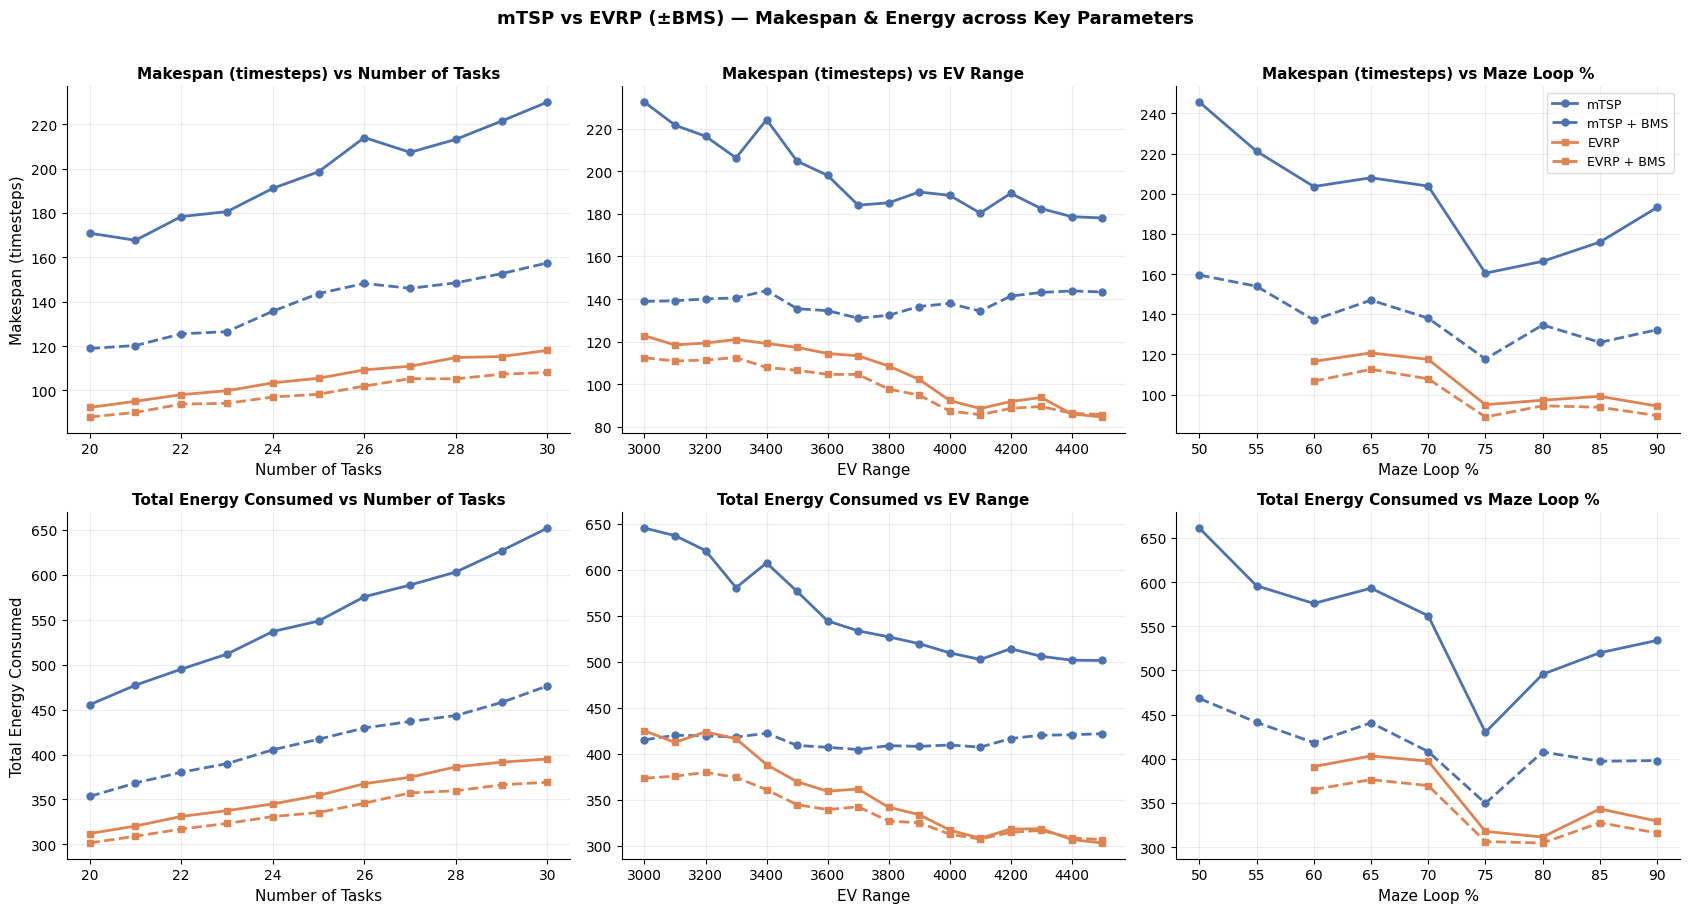

In [9]:

# ── Load latest data (bms col = 0/1 distinguishes variants) ─────────────────
df_mtsp_all = pd.read_csv("runs/iros_26/results_mtsp_latest.csv")
df_evrp_all = pd.read_csv("runs/iros_26/results_evrp_latest.csv")

for _df in (df_mtsp_all, df_evrp_all):
    _df['energy'] = _df['ev_distance'] + 0.01 * _df['drone_distance']

df_mtsp_nb  = df_mtsp_all[df_mtsp_all['bms'] == 0]
df_mtsp_bms = df_mtsp_all[df_mtsp_all['bms'] == 1]
df_evrp_nb  = df_evrp_all[df_evrp_all['bms'] == 0]
df_evrp_bms = df_evrp_all[df_evrp_all['bms'] == 1]

methods = [
    (df_mtsp_nb,  'mTSP',       '#4C72B0', 'o', '-'),
    (df_mtsp_bms, 'mTSP + BMS', '#4C72B0', 'o', '--'),
    (df_evrp_nb,  'EVRP',       '#DD8452', 's', '-'),
    (df_evrp_bms, 'EVRP + BMS', '#DD8452', 's', '--'),
]

x_params   = ['num_tasks',       'ev_range',  'maze_loop_percentage']
x_labels   = ['Number of Tasks', 'EV Range',  'Maze Loop %']
y_metrics  = [
    ('timesteps', 'Makespan (timesteps)'),
    ('energy',    'Total Energy Consumed'),
]

fig, axs = plt.subplots(2, 3, figsize=(17, 9))

for row, (metric, metric_lbl) in enumerate(y_metrics):
    for col, (param, plbl) in enumerate(zip(x_params, x_labels)):
        ax = axs[row, col]
        for df_m, lbl, color, mk, ls in methods:
            g = df_m.groupby(param).mean(numeric_only=True).reset_index()
            ax.plot(g[param], g[metric],
                    marker=mk, linestyle=ls, color=color,
                    linewidth=2, markersize=5, label=lbl)

        ax.set_xlabel(plbl, fontsize=11)
        if col == 0:
            ax.set_ylabel(metric_lbl, fontsize=11)
        ax.set_title(f'{metric_lbl} vs {plbl}', fontsize=11, fontweight='bold')
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(True, alpha=0.25)
        # Single shared legend — top-right plot
        if row == 0 and col == 2:
            ax.legend(fontsize=9, framealpha=0.7)

fig.suptitle('mTSP vs EVRP (±BMS) — Makespan & Energy across Key Parameters',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()
